# Solving the Traveling Salesman  Problem using Local Search

Points: 10

## The [Traveling Salesman Problem](https://en.wikipedia.org/wiki/Travelling_salesman_problem)

* __Goal:__ Find the shortest tour visiting each of $n$ cities exactly once and returning back to the starting city. Given are pairwise distances between cities, where $d_{i,j}$ is the distance from city $i$ to city $j$.

* __State space:__ Each state represents a tour. The cities are numbered and a tour can be expressed as vector  $\pi$ with the order in which the cities are visited (a [permutation](https://en.wikipedia.org/wiki/Permutation)). That is, $\pi(1)$ is the index of the first city to visit, $\pi(2)$ the index of the second, and so on.

* __Objective function:__ Minimize the tour length. The optimization problem is to find the optimal tour $\pi^*$ through the $n$ cities and returning to the starting city:

  > minimize: $\mathrm{tourlength}(\pi) = d_{\pi(n),\pi(1)} + \sum_{i = 1}^{n-1} d_{\pi(i),\pi(i+1)}$
  >
  > subject to: $\pi \ \text{is a valid permutation vector}$

* __Local moves:__ Exchange two cities in the order.

## Helper functions

In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math
import random

np.set_printoptions(precision=2)
pd.set_option('display.precision', 2)

# make the results repeatable
np.random.seed(1234)

In [35]:
def random_tour(n):
    """Create a random tour"""

    tour = list(range(n))
    random.shuffle(tour)
    return(tour)

random_tour(10)

[7, 3, 0, 6, 2, 5, 8, 9, 4, 1]

In [36]:
from scipy.spatial.distance import pdist
from scipy.spatial.distance import squareform

def random_tsp(n):
    """
    Create a random (Euclidean) traveling salesman problem. Choose n points randomly in a 1 x 1 unit square and calulates a
    pairwise Euclidean distance matrix.
    """

    pos = pd.DataFrame({
        "x" : np.random.uniform(size = n),
        "y" : np.random.uniform(size = n)
    })

    dist = squareform(pdist(pos))

    return({"pos": pos, "dist": dist})

tsp = random_tsp(10)

print(f"Positions:\n{tsp['pos']}")
print(f"Distance matrix:\n{pd.DataFrame(tsp['dist'])})")

Positions:
      x     y
0  0.19  0.36
1  0.62  0.50
2  0.44  0.68
3  0.79  0.71
4  0.78  0.37
5  0.27  0.56
6  0.28  0.50
7  0.80  0.01
8  0.96  0.77
9  0.88  0.88
Distance matrix:
      0     1     2     3     4     5     6     7     8     9
0  0.00  0.45  0.41  0.69  0.59  0.22  0.17  0.70  0.87  0.86
1  0.45  0.00  0.26  0.27  0.20  0.35  0.35  0.52  0.43  0.46
2  0.41  0.26  0.00  0.35  0.46  0.21  0.24  0.76  0.53  0.48
3  0.69  0.27  0.35  0.00  0.34  0.53  0.55  0.70  0.18  0.19
4  0.59  0.20  0.46  0.34  0.00  0.54  0.52  0.36  0.44  0.52
5  0.22  0.35  0.21  0.53  0.54  0.00  0.06  0.76  0.72  0.68
6  0.17  0.35  0.24  0.55  0.52  0.06  0.00  0.72  0.73  0.71
7  0.70  0.52  0.76  0.70  0.36  0.76  0.72  0.00  0.77  0.87
8  0.87  0.43  0.53  0.18  0.44  0.72  0.73  0.77  0.00  0.14
9  0.86  0.46  0.48  0.19  0.52  0.68  0.71  0.87  0.14  0.00)


In [37]:
def tour_length(tsp, tour):
    """Caclulate the length of a tour, i.e., the objective function."""

    # make sure tour is a Python list (not an array or a numpy.array)
    if not isinstance(tour, list): tour = tour.tolist()

    tl = 0
    dist = tsp["dist"]

    for i in range(len(tour)-1):
        tl += dist[tour[i], tour[i+1]]

    tl += dist[tour[-1], tour[0]]

    return(tl)

tour = random_tour(10)
tour_length(tsp, tour)

np.float64(4.974877841007605)

Tour length: 4.97


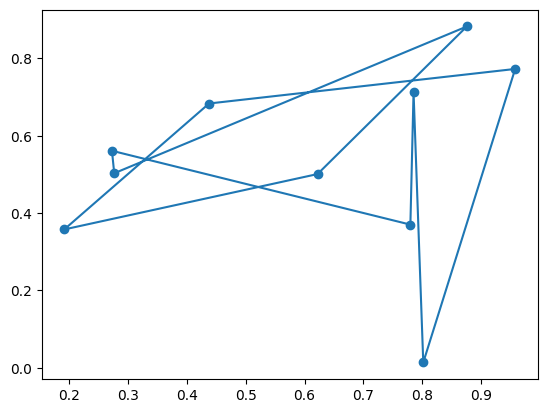

In [38]:
def show_tsp(tsp, tour = None):
    """display the traveling salesman problem and a tour."""

    pos = tsp["pos"]

    plt.scatter(pos["x"], pos["y"])

    if tour is not None:
        # make sure tour is a Python list (not an array or a numpy.array)
        if not isinstance(tour, list): tour = tour.tolist()

        print(f"Tour length: {round(tour_length(tsp, tour), 2)}")

        pos_ = pos.reindex(tour)
        pos_ = pd.concat([pos_, pos_.head(1)])
        plt.plot(pos_["x"], pos_["y"])

    plt.show()

show_tsp(tsp, tour)

## Steepest-ascend Hill Climbing Search [3 Points]

Calculate the objective function for all local moves (move each queen within its column) and always choose the best among all local moves.

In [39]:
def get_neighbors_swap(tour):
    """Sinh tất cả các lân cận bằng cách hoán đổi 2 thành phố bất kỳ"""
    neighbors = []
    n = len(tour)
    for i in range(n):
        for j in range(i + 1, n):
            neighbor = tour.copy()
            neighbor[i], neighbor[j] = neighbor[j], neighbor[i]
            neighbors.append(neighbor)
    return neighbors

def steepest_ascent_tsp(tsp, max_iterations=1000):
    n = len(tsp['pos'])
    current_tour = random_tour(n)
    current_len = tour_length(tsp, current_tour)

    for _ in range(max_iterations):
        neighbors = get_neighbors_swap(current_tour)
        neighbor_lengths = [tour_length(tsp, nb) for nb in neighbors]

        best_neighbor_len = min(neighbor_lengths)
        best_neighbor = neighbors[neighbor_lengths.index(best_neighbor_len)]

        # Dừng nếu kẹt ở Local Optimum
        if best_neighbor_len >= current_len:
            break

        current_tour = best_neighbor
        current_len = best_neighbor_len

    return current_tour, current_len

## Steepest-ascend Hill Climbing Search with Random Restarts [1 Point]

Steepest-ascend with random restarts.

--- KẾT QUẢ SAU KHI CHẠY RANDOM RESTARTS ---
Độ dài tour tối ưu (Random Restarts): 3.82
Thời gian chạy: 106.90 ms
Tour length: 3.82


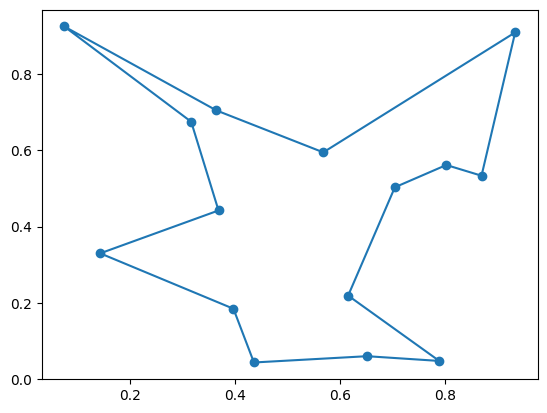

In [40]:
def steepest_ascent_tsp_with_restarts(tsp, num_restarts=10, max_iterations_per_restart=500):
    """
    Thực hiện Steepest-ascent Hill Climbing với nhiều lần khởi động lại ngẫu nhiên (Random Restarts)
    để tránh bị kẹt ở cực trị cục bộ.
    """
    best_tour = None
    best_len = float('inf')
    n = len(tsp['pos'])

    for _ in range(num_restarts):
        # Chạy thuật toán Steepest-ascent từ một trạng thái khởi tạo ngẫu nhiên mới
        current_tour, current_len = steepest_ascent_tsp(tsp, max_iterations=max_iterations_per_restart)

        # Cập nhật kết quả tốt nhất tìm được qua các lần restart
        if current_len < best_len:
            best_len = current_len
            best_tour = current_tour.copy()

    return best_tour, best_len

# --- Test thử thuật toán Random Restarts trên TSP ---
print("--- KẾT QUẢ SAU KHI CHẠY RANDOM RESTARTS ---")
my_tsp = random_tsp(15)

t0 = time.time()
best_restart_tour, restart_len = steepest_ascent_tsp_with_restarts(my_tsp, num_restarts=20)
t1 = time.time()

print(f"Độ dài tour tối ưu (Random Restarts): {restart_len:.2f}")
print(f"Thời gian chạy: {(t1 - t0) * 1e3:.2f} ms")
show_tsp(my_tsp, best_restart_tour)

## Stochastic Hill Climbing [1 Points]

Chooses randomly from among all uphill moves.

In [41]:
def stochastic_hill_climbing_tsp(tsp, max_iterations=1000):
    n = len(tsp['pos'])
    current_tour = random_tour(n)
    current_len = tour_length(tsp, current_tour)

    for _ in range(max_iterations):
        neighbors = get_neighbors_swap(current_tour)
        # Lọc ra các lân cận có chiều dài nhỏ hơn (tốt hơn) hiện tại
        better_neighbors = []
        for nb in neighbors:
            nb_len = tour_length(tsp, nb)
            if nb_len < current_len:
                better_neighbors.append((nb, nb_len))

        # Nếu không còn lân cận nào tốt hơn -> Kẹt ở Local Optimum -> Dừng
        if not better_neighbors:
            break

        # Chọn ngẫu nhiên một trong các lân cận tốt
        next_tour, next_len = random.choice(better_neighbors)
        current_tour = next_tour
        current_len = next_len

    return current_tour, current_len

## First-choice Hill Climbing [1 Point]

First-choice hill climbing is a type of stochastic hill climbing that generates one random local neighbor at a time and accept it if it has a better objective function value than the current state.

In [42]:
def first_choice_hill_climbing_tsp(tsp, max_iterations=2000, max_tries=100):
    n = len(tsp['pos'])
    current_tour = random_tour(n)
    current_len = tour_length(tsp, current_tour)

    for _ in range(max_iterations):
        improved = False
        # Thử sinh ngẫu nhiên tối đa max_tries lần để tìm một lân cận tốt hơn
        for _ in range(max_tries):
            i, j = random.sample(range(n), 2)
            neighbor = current_tour.copy()
            neighbor[i], neighbor[j] = neighbor[j], neighbor[i]

            neighbor_len = tour_length(tsp, neighbor)
            if neighbor_len < current_len:
                current_tour = neighbor
                current_len = neighbor_len
                improved = True
                break # Tìm được cái tốt hơn là nhảy vào luôn (First-choice)

        # Nếu duyệt qua max_tries lần mà không tìm thấy cải thiện nào -> Dừng
        if not improved:
            break

    return current_tour, current_len

## Simulated Annealing [2 Points]

In [43]:
import math

def simulated_annealing_tsp(tsp, initial_temp=100, cooling_rate=0.99, max_iterations=2000):
    n = len(tsp['pos'])
    current_tour = random_tour(n)
    current_len = tour_length(tsp, current_tour)

    best_tour = current_tour.copy()
    best_len = current_len
    T = initial_temp

    for _ in range(max_iterations):
        if T < 1e-5:
            break

        # Sinh ngẫu nhiên 1 lân cận (First-choice)
        i, j = random.sample(range(n), 2)
        neighbor = current_tour.copy()
        neighbor[i], neighbor[j] = neighbor[j], neighbor[i]

        neighbor_len = tour_length(tsp, neighbor)
        delta_E = neighbor_len - current_len

        # Nếu tốt hơn hoặc chấp nhận theo xác suất Boltzmann khi xấu hơn
        if delta_E < 0 or random.random() < math.exp(-delta_E / T):
            current_tour = neighbor
            current_len = neighbor_len

            if current_len < best_len:
                best_len = current_len
                best_tour = current_tour.copy()

        # Giảm nhiệt độ
        T *= cooling_rate

    return best_tour, best_len

## Compare Performance [2 Points]

Use runtime, scalability (number of cities), and best objective function value to compare the algorithms on boards of different sizes.  

For timing you can use the `time` package.

In [44]:
import time

t0 = time.time()
print("Do something")
t1 = time.time()

print(f"This took: {(t1-t0) * 1e3} milliseconds")

Do something
This took: 0.171661376953125 milliseconds


In [45]:
import time
import pandas as pd

# Khởi tạo danh sách lưu kết quả
results = []
# Các kích thước bài toán (số thành phố) để kiểm tra khả năng mở rộng (scalability)
N_sizes = [10, 15, 20]

print("Đang chạy thử nghiệm so sánh... (vui lòng đợi vài giây)\n")

for n in N_sizes:
    tsp_instance = random_tsp(n)

    # 1. Steepest-ascent
    t0 = time.time()
    _, len_hc = steepest_ascent_tsp(tsp_instance, max_iterations=500)
    time_hc = (time.time() - t0) * 1000

    # 2. Random Restart (Chạy 5 lần restart)
    t0 = time.time()
    _, len_rr = steepest_ascent_tsp_with_restarts(tsp_instance, num_restarts=5, max_iterations_per_restart=200)
    time_rr = (time.time() - t0) * 1000

    # 3. Stochastic
    t0 = time.time()
    _, len_stoc = stochastic_hill_climbing_tsp(tsp_instance, max_iterations=500)
    time_stoc = (time.time() - t0) * 1000

    # 4. First-choice
    t0 = time.time()
    _, len_fc = first_choice_hill_climbing_tsp(tsp_instance, max_iterations=500)
    time_fc = (time.time() - t0) * 1000

    # 5. Simulated Annealing
    t0 = time.time()
    _, len_sa = simulated_annealing_tsp(tsp_instance, initial_temp=100, cooling_rate=0.95, max_iterations=1000)
    time_sa = (time.time() - t0) * 1000

    # Ghi nhận kết quả định dạng "Độ dài tour / Thời gian (ms)"
    results.append({
        'N (Số thành phố)': n,
        'Steepest HC': f"{len_hc:.2f} / {time_hc:.1f}ms",
        'Random Restart': f"{len_rr:.2f} / {time_rr:.1f}ms",
        'Stochastic HC': f"{len_stoc:.2f} / {time_stoc:.1f}ms",
        'First-choice': f"{len_fc:.2f} / {time_fc:.1f}ms",
        'Simulated Annealing': f"{len_sa:.2f} / {time_sa:.1f}ms"
    })

# Hiển thị bảng kết quả so sánh
df_results = pd.DataFrame(results)
df_results.set_index('N (Số thành phố)', inplace=True)
display(df_results)

Đang chạy thử nghiệm so sánh... (vui lòng đợi vài giây)



,Steepest HC,Random Restart,Stochastic HC,First-choice,Simulated Annealing
N (Số thành phố),,,,,
10,3.38 / 1.2ms,3.38 / 5.5ms,3.55 / 1.2ms,3.55 / 1.8ms,3.55 / 2.5ms
15,3.91 / 6.9ms,3.62 / 32.8ms,3.52 / 15.2ms,4.25 / 1.9ms,3.88 / 2.5ms
20,4.23 / 17.7ms,3.83 / 99.1ms,4.43 / 44.0ms,4.32 / 5.9ms,6.10 / 4.8ms


## Bonus: Genetic Algorithm [+1 Point]

--- KẾT QUẢ THUẬT TOÁN DI TRUYỀN (GENETIC ALGORITHM) ---
Độ dài tour tối ưu (GA): 2.98
Thời gian chạy: 646.40 ms
Tour length: 2.98


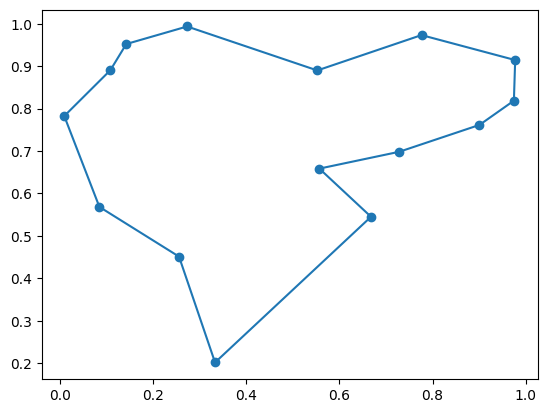

In [46]:
def selection(population, tsp, k=3):
    """Lựa chọn cá thể bằng phương pháp đấu vòng loại (Tournament Selection)"""
    selected = random.sample(population, k)
    selected.sort(key=lambda tour: tour_length(tsp, tour))
    return selected[0]

def crossover(parent1, parent2):
    """Lai ghép OX (Order Crossover) giữ nguyên thứ tự các thành phố"""
    n = len(parent1)
    child = [-1] * n
    start, end = sorted(random.sample(range(n), 2))

    # Lấy 1 đoạn gen từ Cha/Mẹ 1
    child[start:end] = parent1[start:end]

    # Điền các thành phố còn thiếu từ Cha/Mẹ 2
    p2_idx = 0
    for i in range(n):
        if child[i] == -1:
            while parent2[p2_idx] in child:
                p2_idx += 1
            child[i] = parent2[p2_idx]
    return child

def mutate(tour, mutation_rate=0.1):
    """Đột biến hoán đổi vị trí 2 thành phố (Swap Mutation)"""
    if random.random() < mutation_rate:
        i, j = random.sample(range(len(tour)), 2)
        tour[i], tour[j] = tour[j], tour[i]
    return tour

def genetic_algorithm_tsp(tsp, pop_size=50, generations=200, mutation_rate=0.1):
    n = len(tsp['pos'])
    # Khởi tạo quần thể ban đầu ngẫu nhiên
    population = [random_tour(n) for _ in range(pop_size)]

    best_tour = None
    best_len = float('inf')

    for _ in range(generations):
        new_population = []

        # Tìm cá thể xuất sắc nhất thế hệ hiện tại
        for tour in population:
            t_len = tour_length(tsp, tour)
            if t_len < best_len:
                best_len = t_len
                best_tour = tour.copy()

        # Sinh thế hệ mới
        for _ in range(pop_size):
            parent1 = selection(population, tsp)
            parent2 = selection(population, tsp)
            child = crossover(parent1, parent2)
            child = mutate(child, mutation_rate)
            new_population.append(child)

        population = new_population

    return best_tour, best_len

# --- Chạy thử nghiệm Genetic Algorithm ---
print("--- KẾT QUẢ THUẬT TOÁN DI TRUYỀN (GENETIC ALGORITHM) ---")
my_tsp = random_tsp(15)

t0 = time.time()
best_ga_tour, ga_len = genetic_algorithm_tsp(my_tsp, pop_size=50, generations=300, mutation_rate=0.1)
t1 = time.time()

print(f"Độ dài tour tối ưu (GA): {ga_len:.2f}")
print(f"Thời gian chạy: {(t1 - t0) * 1e3:.2f} ms")
show_tsp(my_tsp, best_ga_tour)